# Install & imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

print('Imports OK')

Imports OK


# Reconnect paths, load features

In [2]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/PD_EEG_Thesis_Features_v2')
FEAT_DIR     = PROJECT_ROOT / 'data' / 'features'
FIG_DIR      = PROJECT_ROOT / 'figures'
SPLIT_DIR    = PROJECT_ROOT / 'data' / 'split'
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

d = np.load(str(FEAT_DIR / 'features_all.npz'))
node_features, y, subjects = d['node_features'], d['y'], d['subjects']
print(f'Loaded: {node_features.shape}   (samples, T=6, N=60, F=17)')
print(f'PD: {int(y.sum())}   Control: {int((y==0).sum())}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: (3915, 6, 60, 17)   (samples, T=6, N=60, F=17)
PD: 2549   Control: 1366


# Fixed subject-wise split

In [3]:
from sklearn.model_selection import train_test_split

unique_subjects = np.unique(subjects)
subject_labels  = np.array([y[subjects == s][0] for s in unique_subjects])

TEST_FRAC, VAL_FRAC, RANDOM_STATE = 0.15, 0.15, 42

train_val_subj, test_subj, train_val_y, _ = train_test_split(
    unique_subjects, subject_labels, test_size=TEST_FRAC,
    stratify=subject_labels, random_state=RANDOM_STATE)

val_frac_adj = VAL_FRAC / (1 - TEST_FRAC)
train_subj, val_subj = train_test_split(
    train_val_subj, test_size=val_frac_adj,
    stratify=train_val_y, random_state=RANDOM_STATE)

assert len(set(train_subj) & set(val_subj)) == 0
assert len(set(train_subj) & set(test_subj)) == 0
assert len(set(val_subj) & set(test_subj)) == 0
print('✓ No subject overlap across splits.')

split_df = pd.DataFrame({
    'subject': list(train_subj) + list(val_subj) + list(test_subj),
    'split':   ['train']*len(train_subj) + ['val']*len(val_subj) + ['test']*len(test_subj)
})
split_df.to_csv(SPLIT_DIR / 'subject_split.csv', index=False)

print(f'\nTrain: {len(train_subj)} subjects   Val: {len(val_subj)} subjects   Test: {len(test_subj)} subjects')

✓ No subject overlap across splits.

Train: 103 subjects   Val: 23 subjects   Test: 23 subjects


# Data quality summary visualization

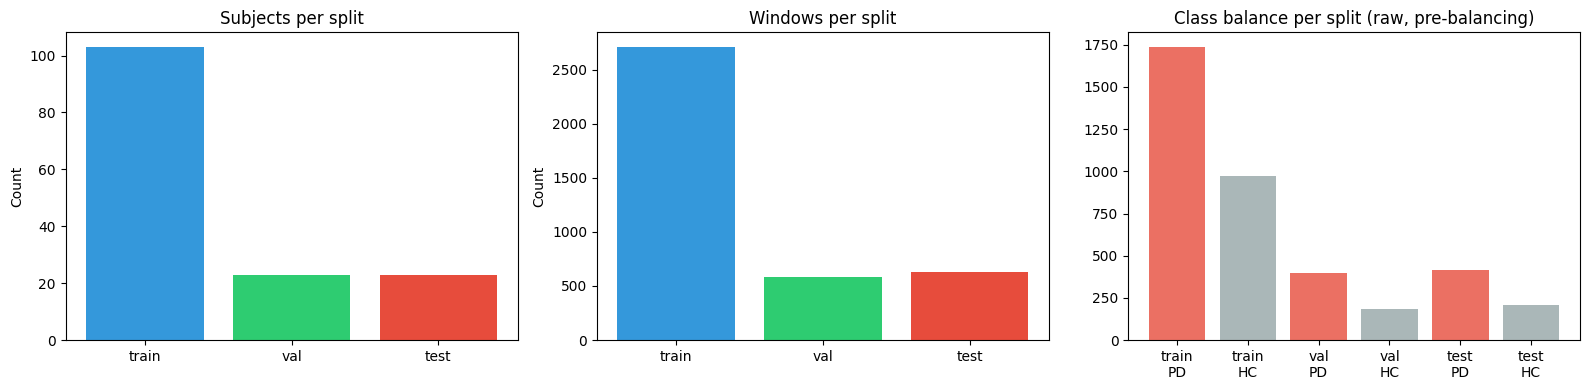

Train — PD: 1737  Control: 972
Val   — PD: 395  Control: 184
Test  — PD: 417  Control: 210


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

split_counts = split_df['split'].value_counts()
axes[0].bar(split_counts.index, split_counts.values, color=['#3498db','#2ecc71','#e74c3c'])
axes[0].set_title('Subjects per split'); axes[0].set_ylabel('Count')

window_mask_train = np.isin(subjects, train_subj)
window_mask_val   = np.isin(subjects, val_subj)
window_mask_test  = np.isin(subjects, test_subj)
window_counts = [window_mask_train.sum(), window_mask_val.sum(), window_mask_test.sum()]
axes[1].bar(['train','val','test'], window_counts, color=['#3498db','#2ecc71','#e74c3c'])
axes[1].set_title('Windows per split'); axes[1].set_ylabel('Count')

for i, (mask, name) in enumerate([(window_mask_train,'train'),(window_mask_val,'val'),(window_mask_test,'test')]):
    pd_n = int(y[mask].sum()); hc_n = int((~y[mask].astype(bool)).sum())
    axes[2].bar([f'{name}\nPD', f'{name}\nHC'], [pd_n, hc_n],
               color=['#e74c3c' if 'PD' in f'{name}PD' else '#3498db']*1 + ['#95a5a6'], alpha=0.8)

axes[2].set_title('Class balance per split (raw, pre-balancing)')
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'preprocessing_split_summary.png'), dpi=130)
plt.show()

print(f'Train — PD: {int(y[window_mask_train].sum())}  Control: {int((~y[window_mask_train].astype(bool)).sum())}')
print(f'Val   — PD: {int(y[window_mask_val].sum())}  Control: {int((~y[window_mask_val].astype(bool)).sum())}')
print(f'Test  — PD: {int(y[window_mask_test].sum())}  Control: {int((~y[window_mask_test].astype(bool)).sum())}')